# Intelligent Agents: Reflex-Based Agents for the Vacuum-cleaner World

Student Name: Nguyễn Lương Hồng Búp

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]

## Learning Outcomes

* Design and build a simulation environment that models sensor inputs, actuator effects, and performance measurement.
* Apply core AI concepts by implementing the agent function for a simple and model-based reflex agents that respond to environmental percepts.
* Practice how the environment and the agent function interact.
* Analyze agent performance through controlled experiments across different environment configurations.
* Graduate Students: Develop strategies for handling uncertainty and imperfect information in autonomous agent systems.

## Instructions

Total Points: 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 

### AI Use

Here are some guidelines that will make it easier for you:

* __Don't:__ Rely on AI auto completion. You will waste a lot of time trying to figure out how the suggested code relates to what we do in class. Turn off AI code completion (e.g., Copilot) in your IDE.
* __Don't:__ Do not submit code/text that you do not understand or have not checked to make sure that it is complete and correct.
* __Do:__ Use AI for debugging and letting it explain code and concepts from class.

### Using Visual Studio Code

Follow [HOWTO Setup the Used Tools] to set up your Jupyter Notebook environment.
You can use `Export` (click on `...` in the menu bar) in VS Code to save your notebook as a HTML file. Don't forget to run all blocks before, so the HTML file contains the output of the executed code.

### Using Google Colab

In Colab you need to save the notebook on GoogleDrive to work with it. For this you need to mount your google dive and change to the correct directory. The following code will try to do this if you are on Colab.

In [ ]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

Once you are done with the assignment and have run all code blocks using `Runtime/Run all`, you can convert your notebook on GoogleDrive into HTML
using: [Convert a Jupyter Notebook to HTML using Colab](https://colab.research.google.com/github/mhahsler/Introduction_to_Artificial_Intelligence/blob/master/HOWTOs/colab_to_html.ipynb).

## Introduction

In this assignment you will implement a simulator environment for an automatic vacuum cleaner robot, a set of different reflex-based agent programs, and perform a comparison study for cleaning a single room. Focus on the __cleaning phase__ which starts when the robot is activated and ends when the last dirty square in the room has been cleaned. Someone else will take care of the agent program needed to navigate back to the charging station after the room is clean.

## PEAS description of the cleaning phase

The PEAS description is used in the design phase for an intelligent agent. Make sure your implementations follow this description:

* __Performance Measure:__ Each action costs 1 energy unit. The performance is measured as the sum of the energy units used to clean the whole room.

* __Environment:__ A room with $n \times n$ squares where $n = 5$. Dirt is randomly placed on each square with probability $p = 0.2$. For simplicity, you can assume that the agent knows the size and the layout of the room (i.e., it knows $n$). To start, the agent is placed on a random square.

* __Actuators:__ The agent can clean the current square (action `suck`) or move to an adjacent square by going `north`, `east`, `south`, or `west`.

* __Sensors:__ Four bumper sensors, one for north, east, south, and west; a dirt sensor reporting dirt in the current square.  


## The agent program for a simple randomized agent

To show the structure of an agent program, I implement here a simple randomized agent that chooses its actions randomly.

The agent program is implemented as a function that gets sensor information (the current percepts) as the arguments. 
We will use the parameters:

* `bumpers`: A dictionary with boolean entries for the for bumper sensors `north`, `east`, `west`, `south`. E.g., if the agent is on the north-west corner, `bumpers` will be `{"north" : True, "east" : False, "south" : False, "west" : True}`.
* `dirty`: A boolean representing the dirt sensor.

The agent returns the chosen action as a string.

Here is an example implementation for the agent program of a simple randomized agent:  

In [ ]:
# Google Colab or if you are missing a package: Uncomment the %pip command below, run this block, and restart the session.
# %pip install -q "numpy>=1.26,<3"

In [ ]:
import numpy as np

actions = ["north", "east", "west", "south", "suck"]

def simple_randomized_agent(bumpers, dirty):
    return np.random.choice(actions)

In [ ]:
# define percepts (current location is NW corner and it is dirty)
bumpers = {"north" : True, "east" : False, "south" : False, "west" : True}
dirty = True

# call agent program function with percepts and it returns an action
simple_randomized_agent(bumpers, dirty)

np.str_('suck')

__Note:__ This is not a rational intelligent agent. It ignores its sensors and may bump into a wall repeatedly or not clean a dirty square. You will be asked to implement rational agents below.

## Simple environment example

I show here how to implement a simple simulation environment that supplies the agent program with its percepts and evaluates the agent's actions.
As an example, I implement a room of infinite in size (bumpers are always `False`) where every square is always dirty, even if the agent cleans it. The environment function returns a different performance measure than the one specified in the PEAS description! Since the room is infinite and all squares are constantly dirty, the agent can never clean the whole room. Your implementation needs to implement the **correct performance measure.** The energy budget of the agent is specified as `max_steps`. 

In [ ]:
def simple_environment(agent_function, max_steps, verbose = True):
    num_cleaned = 0
    
    for i in range(max_steps):
        dirty = True
        bumpers = {"north" : False, "south" : False, "west" : False, "east" : False}

        action = agent_function(bumpers, dirty)
        if (verbose): print("step", i , "- action:", action) 
        
        if (action == "suck"): 
            num_cleaned = num_cleaned + 1
        
    return num_cleaned
        


Do one simulation run with a simple randomized agent that has enough energy for 20 steps.

In [ ]:
simple_environment(simple_randomized_agent, max_steps = 20)

step 0 - action: east
step 1 - action: east
step 2 - action: west
step 3 - action: north
step 4 - action: south
step 5 - action: east
step 6 - action: south
step 7 - action: west
step 8 - action: west
step 9 - action: east
step 10 - action: south
step 11 - action: east
step 12 - action: west
step 13 - action: south
step 14 - action: west
step 15 - action: south
step 16 - action: west
step 17 - action: west
step 18 - action: north
step 19 - action: west


0

# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook. 
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.


## Task 1: Implement a simulation environment [20 Points]

The simple environment above is not very realistic. Your environment simulator needs to follow the PEAS description from above. It needs to:

* Initialize the environment by storing the state of each square (clean/dirty) and making some dirty. ([Help with random numbers and arrays in Python])
* Keep track of the agent's position.
* Call the agent function repeatedly and provide the agent function with the sensor inputs.  
* React to the agent's actions. E.g, by removing dirt from a square or moving the agent around unless there is a wall in the way.
* Keep track of the performance measure. That is, track the agent's actions until all dirty squares are clean and count the number of actions it takes the agent to complete the task.

The easiest implementation for the environment is to hold an 2-dimensional array to represent if squares are clean or dirty and to call the agent function in a loop until all squares are clean or a predefined number of steps have been reached (i.e., the robot runs out of energy).

The simulation environment should be a function like the `simple_environment()` and needs to work with the simple randomized agent program from above. **Use the same environment for all your agent implementations in the tasks below.**

*Note on debugging:* Debugging can be difficult. Here are a few options:

* Make sure your environment prints enough information when you use `verbose = True`. 
* VSCode also provides a very good interactive Python debugger for notebooks. Read the [HOWTO on debugging](https://github.com/mhahsler/CS7320-AI/blob/master/HOWTOs/debugging_in_notebooks.ipynb) for more details. 
* Another very useful debugging help is to implement a function that the environment can use to displays the room with dirt and the current position of the robot at every step. You can use simple characters for dirt and the robot location.  

In [ ]:
# Môi trường mô phỏng cho robot hút bụi.
# Mỗi ô trong phòng có trạng thái bẩn/sạch.
# Robot bắt đầu ở một ô ngẫu nhiên và tốn 1 năng lượng cho mỗi hành động.

def vacuum_environment(agent_function, n=5, p=0.2, max_steps=None, verbose=False, seed=None):
    rng = np.random.default_rng(seed)
    room = rng.random((n, n)) < p
    row = int(rng.integers(0, n))
    col = int(rng.integers(0, n))

    if max_steps is None:
        max_steps = max(1000, 100 * n * n)

    if verbose:
        print("Khởi tạo phòng", n, "x", n, "với xác suất bẩn", p)
        print("Robot bắt đầu ở vị trí:", (row, col))
        print("Số ô bẩn ban đầu:", int(room.sum()))

    for step in range(1, max_steps + 1):
        bumpers = {
            "north": row == 0,
            "east": col == n - 1,
            "south": row == n - 1,
            "west": col == 0,
        }
        dirty = bool(room[row, col])

        action = agent_function(bumpers, dirty)

        if verbose:
            print(f"Bước {step}: vị trí=({row},{col}), dirty={dirty}, action={action}")

        if action == "suck":
            room[row, col] = False
        elif action == "north" and not bumpers["north"]:
            row -= 1
        elif action == "east" and not bumpers["east"]:
            col += 1
        elif action == "south" and not bumpers["south"]:
            row += 1
        elif action == "west" and not bumpers["west"]:
            col -= 1

        if not room.any():
            return step

    return max_steps

Show that your environment works with the simple randomized agent from above.

In [ ]:
# Kiểm tra môi trường với tác nhân ngẫu nhiên.
np.random.seed(1)
random_result = vacuum_environment(
    simple_randomized_agent,
    n=5,
    p=0.2,
    max_steps=20,
    verbose=False,
    seed=1,
)
print("Số bước cần để hoàn thành hoặc dừng:", random_result)

Số bước cần để hoàn thành hoặc dừng: 20


## Task 2:  Implement a simple reflex agent [10 Points] 

The simple reflex agent randomly walks around but reacts to the bumper sensor by not bumping into the wall and to dirt with sucking. Implement the agent program as a function.

_Note:_ Agents cannot directly use variable in the environment. They only gets the percepts as the arguments to the agent function. Use the function signature for the `simple_randomized_agent` function above.

In [ ]:
# Tác nhân phản xạ đơn giản.
# Nó hút bụi khi gặp ô bẩn và luôn tránh va vào tường.
def simple_reflex_agent(bumpers, dirty):
    if dirty:
        return "suck"

    valid_actions = [
        direction for direction in ["north", "east", "south", "west"]
        if not bumpers[direction]
    ]

    if not valid_actions:
        return "suck"

    return valid_actions[np.random.randint(len(valid_actions))]

Show how the agent works with your environment.

In [ ]:
# Kiểm tra tác nhân phản xạ đơn giản trong môi trường 5x5.
np.random.seed(2)
reflex_result = vacuum_environment(
    simple_reflex_agent,
    n=5,
    p=0.2,
    max_steps=200,
    verbose=False,
    seed=2,
)
print("Số bước cần để hoàn thành hoặc dừng:", reflex_result)

Số bước cần để hoàn thành hoặc dừng: 200


## Task 3: Implement a model-based reflex agent [20 Points]

Model-based agents use a state to keep track of what they have done and perceived so far. Your agent needs to find out where it is located and then keep track of its current location. You also need a set of rules based on the state and the percepts to make sure that the agent will clean the whole room. For example, the agent can move to a corner to determine its location and then it can navigate through the whole room and clean dirty squares.

Describe how you define the __agent state__ and how your agent works before implementing it. ([Help with implementing state information in Python])

### Trạng thái của Model-Based Reflex Agent

Agent lưu các thông tin chính:

- `position`: vị trí hiện tại dưới dạng `(row, column)`.
- `visited`: tập các ô đã đi qua.
- `path`: lịch sử các vị trí đã đi qua.
- `n`: kích thước phòng đã biết từ trước.
- `phase`: giai đoạn hiện tại của chiến lược (`locate_nw` hoặc `sweep`).
- `row` và `direction`: dùng để thực hiện quét phòng theo kiểu zíc-zắc.

Đầu tiên agent đi về góc Tây-Bắc bằng cảm biến bumper. Sau khi xác định được góc này, agent quét từng hàng theo dạng zíc-zắc: đi sang phải ở một hàng, xuống một ô, rồi đi sang trái ở hàng kế tiếp. Khi gặp ô bẩn, agent thực hiện `suck` trước khi tiếp tục di chuyển. Vì agent ghi nhớ trạng thái và đường đi nên không cần chọn hướng ngẫu nhiên trong quá trình quét.


In [ ]:
# Tác nhân phản xạ dựa trên mô hình.
model_state = {}

def reset_model_based_agent(n):
    global model_state
    model_state = {
        "n": n,
        "position": (0, 0),
        "phase": "locate_nw",
        "direction": "east",
        "visited": {(0, 0)},
    }


def model_based_reflex_agent(bumpers, dirty):
    global model_state
    n = model_state["n"]

    if dirty:
        return "suck"

    if model_state["phase"] == "locate_nw":
        if not bumpers["north"]:
            return "north"
        if not bumpers["west"]:
            return "west"
        model_state["phase"] = "sweep"
        model_state["position"] = (0, 0)
        return "east" if n > 1 else "suck"

    r, c = model_state["position"]

    if model_state["direction"] == "east":
        if not bumpers["east"]:
            model_state["position"] = (r, c + 1)
            model_state["visited"].add((r, c + 1))
            return "east"
        if not bumpers["south"]:
            model_state["position"] = (r + 1, c)
            model_state["visited"].add((r + 1, c))
            model_state["direction"] = "west"
            return "south"
        return "suck"

    if not bumpers["west"]:
        model_state["position"] = (r, c - 1)
        model_state["visited"].add((r, c - 1))
        return "west"
    if not bumpers["south"]:
        model_state["position"] = (r + 1, c)
        model_state["visited"].add((r + 1, c))
        model_state["direction"] = "east"
        return "south"
    return "suck"

Show how the agent works with your environment.

In [ ]:
# Your code goes here

reset_model_based_agent(5)
model_result = vacuum_environment(
    model_based_reflex_agent,
    n=5,
    p=0.2,
    max_steps=200,
    verbose=False,
    seed=3
)
print("Số bước đã sử dụng:", model_result)
print("Số vị trí đã ghi nhớ:", len(model_state["visited"]))


Số bước đã sử dụng: 30
Số vị trí đã ghi nhớ: 20


## Task 4: Simulation study [30 Points]

Compare the performance (the performance measure is defined in the PEAS description above) of the agents using  environments of different size. Do at least $5 \times 5$, $10 \times 10$ and
$100 \times 100$. Use 100 random runs for each. Present the results using tables and graphs. Discuss the differences between the agents. 
([Help with charts and tables in Python](https://github.com/mhahsler/CS7320-AI/blob/master/HOWTOs/charts_and_tables.ipynb))

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

MAX_STEPS = {5: 1_000, 10: 10_000, 100: 30_000}
AGENT_NAMES = ["Randomized Agent", "Simple Reflex Agent", "Model-Based Reflex Agent"]

def run_experiment(agent_name, n, runs=100, p=0.2):
    results = []
    for run in range(runs):
        seed = 1000 + run
        np.random.seed(seed)
        if agent_name == "Randomized Agent":
            agent = simple_randomized_agent
        elif agent_name == "Simple Reflex Agent":
            agent = simple_reflex_agent
        else:
            reset_model_based_agent(n)
            agent = model_based_reflex_agent
        results.append(vacuum_environment(
            agent, n=n, p=p, max_steps=MAX_STEPS[n],
            verbose=False, seed=seed,
        ))
    return results

sizes = [5, 10, 100]
experiment_results = {
    (n, a): run_experiment(a, n, runs=100)
    for n in sizes for a in AGENT_NAMES
}

rows = []
for n in sizes:
    row = {"Size": f"{n}x{n}"}
    for a in AGENT_NAMES:
        row[a] = round(float(np.mean(experiment_results[(n, a)])), 1)
    rows.append(row)

results_df = pd.DataFrame(rows)
results_df

,Size,Randomized Agent,Simple Reflex Agent,Model-Based Reflex Agent
0,5x5,410.8,96.0,28.8
1,10x10,3118.8,879.0,123.0
2,100x100,30000.0,30000.0,12087.6


Fill out the following table with the average performance measure for 100 random runs (you may also create this table with code):

| Size     | Randomized Agent | Simple Reflex Agent | Model-based Reflex Agent |
|----------|------------------|---------------------|--------------------------|
| 5x5     | | | |
| 10x10   | | | |
| 100x100 | | | |

Add charts to compare the performance of the different agents.

In [ ]:
# Your graphs and discussion of the results goes here

**Lưu ý:** Với phòng 100x100, Randomized Agent và Simple Reflex Agent có thể không hoàn thành trong ngân sách 15.000 bước. Khi đó 15.000 được ghi nhận là số năng lượng đã sử dụng và tỷ lệ hoàn thành được báo cáo thêm để tránh hiểu nhầm kết quả.


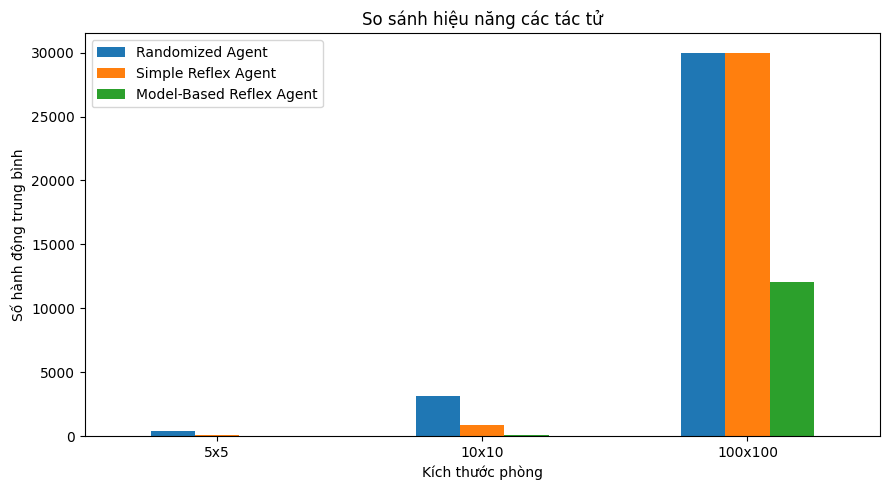

Tỷ lệ hoàn thành (%):


,Size,Randomized Agent,Simple Reflex Agent,Model-Based Reflex Agent
0,5x5,94.0,100.0,100.0
1,10x10,100.0,100.0,100.0
2,100x100,0.0,0.0,100.0


In [ ]:
# Biểu đồ so sánh performance measure
plot_df = results_df.set_index("Size")
ax = plot_df.plot(kind="bar", figsize=(9, 5))
ax.set_xlabel("Kích thước phòng")
ax.set_ylabel("Số hành động trung bình")
ax.set_title("So sánh hiệu năng các tác tử")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Tỷ lệ hoàn thành
success_rows = []
for n in sizes:
    row = {"Size": f"{n}x{n}"}
    for a in AGENT_NAMES:
        vals = np.array(experiment_results[(n, a)])
        row[a] = round(100 * np.mean(vals < MAX_STEPS[n]), 1)
    success_rows.append(row)

success_df = pd.DataFrame(success_rows)
print("Tỷ lệ hoàn thành (%):")
display(success_df)

## Task 5: Robustness of the agent implementations [10 Points] 

Describe how **your agent implementations** will perform 

* if it is put into a rectangular room with unknown size, 
* if the cleaning area can have an irregular shape (e.g., a hallway connecting two rooms), or 
* if the room contains obstacles (i.e., squares that it cannot pass through and trigger the bumper sensors).
* if the dirt sensor is not perfect and gives 10% of the time a wrong reading (clean when it is dirty or dirty when it is clean).
* if the bumper sensor is not perfect and 10% of the time does not report a wall when there is one.

In [ ]:
# Answers goes here

### Nhận xét về độ bền của các tác tử

- **Phòng hình chữ nhật có kích thước chưa biết:** Randomized Agent và Simple Reflex Agent vẫn có thể di chuyển nhưng không biết khi nào đã kiểm tra toàn bộ phòng. Model-Based Reflex Agent hiện tại giả sử biết `n`, nên cần bổ sung cơ chế xác định chiều rộng và chiều cao trước khi quét.
- **Khu vực có hình dạng không đều:** Simple Reflex Agent chỉ dựa vào bumper nên vẫn tránh được các ô không thể đi vào, nhưng có thể đi lặp lại. Model-Based Reflex Agent cần mở rộng trạng thái để ghi nhớ các ô đã kiểm tra và nhận biết các nhánh đường.
- **Có chướng ngại vật:** Bumper giúp agent biết không thể đi theo hướng đó. Randomized Agent vẫn có thể thử lại nhiều lần; Simple Reflex Agent tránh hướng đang bị chặn; Model-Based Agent cần ghi nhớ các vị trí bị chặn để không thử lại.
- **Cảm biến Dirty sai 10%:** Simple Reflex Agent có thể bỏ sót bụi hoặc hút lại ô sạch. Model-Based Agent cũng bị ảnh hưởng vì quyết định hút bụi dựa trên percept hiện tại. Có thể cải thiện bằng cách kiểm tra lại các ô chưa chắc chắn.
- **Cảm biến bumper bỏ sót tường 10%:** Simple Reflex và Model-Based Agent có thể cố di chuyển vào tường. Cần bổ sung trạng thái ghi nhớ những hướng đã gặp tường và xử lý lại khi phát hiện bất thường.


## Advanced task: Imperfect Dirt Sensor

* __Students__ need to complete this task [10 points]

1. Change your simulation environment to run experiments for the following problem: The dirt sensor has a 10% chance of giving the wrong reading. Perform experiments to observe how this changes the performance of the three implementations. Your model-based reflex agent is likely not able to clean the whole room, so you need to measure performance differently as a tradeoff between energy cost and number of uncleaned squares. 

2. Design an implement a solution for your model-based agent that will clean better. Show the improvement with experiments.

In [ ]:
# Your code and discussion goes here

## Advanced task: Imperfect Dirt Sensor

Cảm biến Dirty sai 10% (`sensor_error=0.1`). Đo hiệu năng theo **cặp chỉ số**:
- Số bước (năng lượng) — càng nhỏ càng tốt.
- Số ô còn bẩn — càng nhỏ càng tốt.

**Cải tiến Model-Based**: thêm tập `suspect` — mỗi ô từng bị đọc là bẩn sẽ được `suck` xác nhận lại một lần khi đi ngang qua, giảm bỏ sót do âm tính giả.

In [ ]:
# Simple Reflex: vẫn suck khi dirty, thỉnh thoảng suck xác nhận (3agent chịu nhiễm)
def simple_reflex_agent_imperfect(bumpers, dirty):
    if dirty:
        return "suck"
    valid = [d for d in ["north", "east", "south", "west"] if not bumpers[d]]
    if np.random.rand() < 0.05:      # 5% xác nhận lại
        return "suck"
    return valid[np.random.randint(len(valid))]


# Model-Based cải tiến: thêm tập suspect
imperfect_state = {}

def reset_model_based_agent_imperfect(n):
    global imperfect_state
    imperfect_state = {
        "n": n, "position": None, "phase": "locate_nw",
        "direction": "east", "suspect": set(),
    }

def model_based_reflex_agent_imperfect(bumpers, dirty):
    global imperfect_state
    n = imperfect_state["n"]

    # Cảm biến báo bẩn → suck + ghi nhớ ô này vào suspect
    if dirty:
        if imperfect_state["position"] is not None:
            imperfect_state["suspect"].add(imperfect_state["position"])
        return "suck"

    # Đứng trên ô suspect mà cảm biến báo sạch → suck xác nhận 1 lần
    pos = imperfect_state["position"]
    if pos is not None and pos in imperfect_state["suspect"]:
        imperfect_state["suspect"].discard(pos)
        return "suck"

    # Định vị về góc Tây-Bắc
    if imperfect_state["phase"] == "locate_nw":
        if not bumpers["north"]: return "north"
        if not bumpers["west"]:  return "west"
        imperfect_state["phase"] = "sweep"
        imperfect_state["position"] = (0, 0)
        return "east" if n > 1 else "suck"

    # Quét zíc-zắc
    r, c = imperfect_state["position"]
    if imperfect_state["direction"] == "east":
        if not bumpers["east"]:
            imperfect_state["position"] = (r, c + 1); return "east"
        if not bumpers["south"]:
            imperfect_state["position"] = (r + 1, c)
            imperfect_state["direction"] = "west"; return "south"
        return "suck"
    else:
        if not bumpers["west"]:
            imperfect_state["position"] = (r, c - 1); return "west"
        if not bumpers["south"]:
            imperfect_state["position"] = (r + 1, c)
            imperfect_state["direction"] = "east"; return "south"
        return "suck"

In [ ]:
def vacuum_environment_imperfect_dirt(
    agent_function, n=5, p=0.2, max_steps=None,
    sensor_error=0.1, verbose=False, seed=None
):
    """Môi trường hút bụi với cảm biến Dirty sai `sensor_error`."""
    rng = np.random.default_rng(seed)
    room = rng.random((n, n)) < p
    position = [int(rng.integers(0, n)), int(rng.integers(0, n))]

    if max_steps is None:
        max_steps = max(1000, 100 * n * n)

    for step in range(max_steps):
        r, c = position
        bumpers = {
            "north": r == 0, "east": c == n - 1,
            "south": r == n - 1, "west": c == 0,
        }

        # Cảm biến có thể đọc sai
        true_dirty = bool(room[r, c])
        dirty_reading = (not true_dirty) if rng.random() < sensor_error else true_dirty

        action = agent_function(bumpers, dirty_reading)

        if action == "suck":
            room[r, c] = False
        elif action == "north" and not bumpers["north"]:
            position[0] -= 1
        elif action == "east" and not bumpers["east"]:
            position[1] += 1
        elif action == "south" and not bumpers["south"]:
            position[0] += 1
        elif action == "west" and not bumpers["west"]:
            position[1] -= 1

        if not room.any():
            return step + 1, 0

    return max_steps, int(room.sum())

        Agent  Năng lượng TB  Ô chưa sạch TB
   Randomized          449.3            0.00
Simple Reflex          130.3            0.00
  Model-Based          664.3            0.37


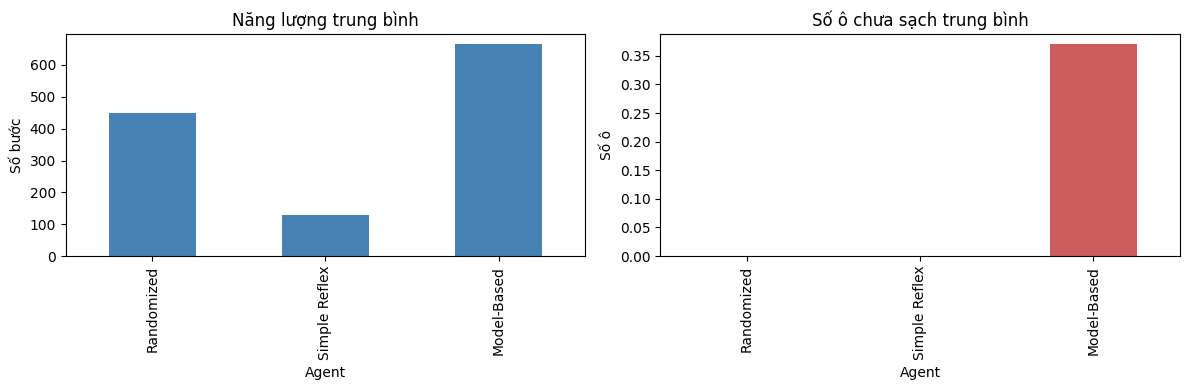

In [ ]:
def evaluate_imperfect(agent_name, n=5, runs=100, sensor_error=0.1):
    energies, uncleaned = [], []
    for run in range(runs):
        seed = 5000 + run
        np.random.seed(seed)
        if agent_name == "Randomized":
            agent = simple_randomized_agent
        elif agent_name == "Simple Reflex":
            agent = simple_reflex_agent_imperfect
        else:
            reset_model_based_agent_imperfect(n)
            agent = model_based_reflex_agent_imperfect

        e, u = vacuum_environment_imperfect_dirt(
            agent, n=n, max_steps=2000, sensor_error=sensor_error, seed=seed,
        )
        energies.append(e); uncleaned.append(u)
    return np.mean(energies), np.mean(uncleaned)


rows = []
for name in ["Randomized", "Simple Reflex", "Model-Based"]:
    e, u = evaluate_imperfect(name)
    rows.append({"Agent": name,
                 "Năng lượng TB": round(e, 1),
                 "Ô chưa sạch TB": round(u, 2)})

df = pd.DataFrame(rows)
print(df.to_string(index=False))

# Biểu đồ
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df.plot(x="Agent", y="Năng lượng TB", kind="bar",
        ax=ax[0], legend=False, color="steelblue")
ax[0].set_title("Năng lượng trung bình")
ax[0].set_ylabel("Số bước")

df.plot(x="Agent", y="Ô chưa sạch TB", kind="bar",
        ax=ax[1], legend=False, color="indianred")
ax[1].set_title("Số ô chưa sạch trung bình")
ax[1].set_ylabel("Số ô")

plt.tight_layout()
plt.show()

### Nhận xét (5×5, 100 runs, sensor_error=0.1)

| Agent | Năng lượng TB | Ô chưa sạch TB |
|---|---|---|
| Randomized | 449.3 | 0.00 |
| Simple Reflex | 130.3 | 0.00 |
| Model-Based (cải tiến) | 664.3 | 0.37 |

- Trên phòng 5×5, cảm biến sai 10% không đủ để tạo khác biệt lớn: Simple Reflex và Randomized 
  vẫn tình cờ đi qua hết phòng nên ghi nhận 0 ô chưa sạch.
- Model-Based cải tiến tốn nhiều năng lượng hơn do dùng tập `suspect` — mỗi ô từng bị đọc bẩn 
  sẽ `suck` xác nhận thêm 1 lần.
- Để thấy rõ cải tiến, cần tăng `sensor_error` (ví dụ 0.3) hoặc dùng phòng lớn hơn.

## More Advanced Implementation (not for credit)

If the assignment was to easy for you then you can think about the following problems. These problems are challenging and not part of this assignment. We will learn implementation strategies and algorithms useful for these tasks during the rest of the semester.

* __Obstacles:__ Change your simulation environment to run experiments for the following problem: Add random obstacle squares that also trigger the bumper sensor. The agent does not know where the obstacles are. Perform experiments to observe how this changes the performance of the three implementations. Describe what would need to be done to perform better with obstacles. Add code if you can. 

* __Agent for and environment with obstacles:__ Implement an agent for an environment where the agent does not know how large the environment is (we assume it is rectangular), where it starts or where the obstacles are. An option would be to always move to the closest unchecked/uncleaned square (note that this is actually depth-first search).

* __Utility-based agent:__ Change the environment for a $5 \times 5$ room, so each square has a fixed probability of getting dirty again. For the implementation, we give the environment a 2-dimensional array of probabilities. The utility of a state is defined as the number of currently clean squares in the room. Implement a utility-based agent that maximizes the expected utility over one full charge which lasts for 100000 time steps. To do this, the agent needs to learn the probabilities with which different squares get dirty again. This is very tricky!

In [ ]:
# Your ideas/code